# Проверка окружения

Выберите kernel `Python (pendulum_noise_to_delay)` и выполните все ячейки.

Условия: 1001 точка на интервале от 0 до 2π, сигнал sin(t), без шума. Ожидаются среднее около 0 и средний квадрат 500/1001 с абсолютной погрешностью не более 1e-12. Это проверка окружения, а не модель маятника.

In [1]:
import sys
from pathlib import Path

print(f"Интерпретатор: {sys.executable}")
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
assert Path(sys.prefix).resolve() == project_root / ".venv", (
    "Выберите kernel Python (pendulum_noise_to_delay) и перезапустите его"
)
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import src

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"Исходники: {src.__file__}")

Интерпретатор: /Users/user/projects/Python/pendulum_noise_to_delay/.venv/bin/python
Python: 3.13.1
NumPy: 2.5.4
Исходники: /Users/user/projects/Python/pendulum_noise_to_delay/src/__init__.py


In [2]:
t = np.linspace(0, 2 * np.pi, 1001)
signal = np.sin(t)
mean = signal.mean()
mean_square = np.mean(signal**2)

np.testing.assert_allclose(mean, 0, atol=1e-12, rtol=0)
np.testing.assert_allclose(mean_square, 500 / 1001, atol=1e-12, rtol=0)
print(f"Точек: {signal.size}")
print(f"Среднее: {mean:.3e}")
print(f"Средний квадрат: {mean_square:.12f}")

Точек: 1001
Среднее: 0.000e+00
Средний квадрат: 0.499500499500


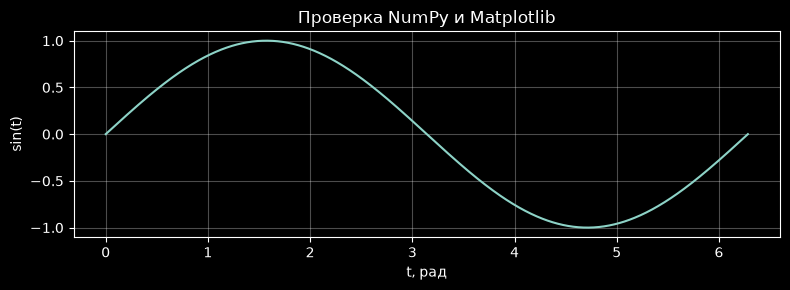

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, signal)
ax.set(xlabel="t, рад", ylabel="sin(t)", title="Проверка NumPy и Matplotlib")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()